# HoloMine Breast Cancer Classification — Task 1 (Hology)
**Tujuan:** klasifikasi mammogram *Normal / Benign / Malignant*, metrik **macro-F1**, test set *patient-disjoint* (54 citra).

### Ringkasan pendekatan
| Tahap | Apa yang dilakukan | Kenapa |
|---|---|---|
| 1. Audit data | Format file JPEG membocorkan kelas **Normal**: semua file mode `L` = Normal (78/78 di train). Test = 20 `L` + 34 `RGB`. | Skor praktis ditentukan oleh **Benign vs Malignant** pada citra RGB. |
| 2. Preprocessing | Mask payudara → hapus teks *burn-in* → crop → orientasi seragam → windowing per-citra. | Menghilangkan *shortcut* non-anatomis (teks view, sisi, background abu-abu). |
| 3. Struktur kasus | Dataset = 133 kasus × 2 citra (CC + MLO payudara yang sama, **label sama**). Pairing direkonstruksi **tanpa label** (67/67 pasangan RGB train berlabel sama). | (a) CV harus *group by woman* — kalau tidak, AUC B-vs-M melambung palsu (probe yang sama pada Mammo-CLIP B5: 0.83 fold per-citra → 0.57 per-kasus → 0.52 per-wanita). (b) Prediksi diputuskan **per kasus**. |
| 4. Model | **Ensemble zero-shot 5 tim**: jaringan mammografi publik yang dilatih pada puluhan ribu mammogram, dipakai **beku tanpa training apa pun di data ini** — (1) juara-1 RSNA 2023, (2) **juara-3 RSNA 2023** (EffNetV2-S 2048×1280, ConvNeXt-nano, CNN+BiLSTM yang membaca CC+MLO sekaligus; data eksternal dengan *lesi jinak = negatif* dan VinDr BI-RADS 4–5 vs 2–3), (3) Theo Viel (EffNetV2-M, ECA-NFNet; CBIS-DDSM + CMMD), (4) **MAM-CLIP** dan (5) **Mergen1** — dua pengklasifikasi **BI-RADS** yang dilatih pada data skrining Turki berlabel impresi radiolog, jenis label yang sama dengan dataset ini (MAM-CLIP adalah pembaca terkuat, AUC 0.86). Tiap keluarga → z-score → skor tim → rata-rata **bobot sama per tim**. | Dengan hanya 66 kasus abnormal, apa pun yang *dilatih* di sini (head, fine-tuning, stacking, encoder generik DINOv2/v3, Mammo-CLIP) **kalah** dari skor zero-shot di CV yang jujur. Peringkat kasus **tidak memakai bobot yang di-fit ke label kita**; satu-satunya keputusan yang melihat label adalah memilih 5 dari 13 tim yang diskor — dampaknya dikoreksi *out-of-bag* di bagian 7. |
| 5. Keputusan | Platt *class-balanced* 2-parameter (di-fit dalam fold) → threshold 0.5 → satu label per kasus. | Threshold hasil tuning & *prior matching* diuji out-of-bag: lebih buruk (−0.03). |

**Ekspektasi jujur (CV aman-per-wanita, 5×5 fold):** AUC kasus B-vs-M ≈ **0.82** setelah koreksi seleksi (in-sample 0.83; v1 yang hanya memakai juara-1: 0.76) → macro-F1 3-kelas ≈ **0.83** dengan aturan format; simulasi test 27-kasus: **≈ 0.83 ± 0.07** (interval 90% ≈ 0.72–0.95; peluang ≥ 0.90 ≈ 15%). **Tanpa** aturan format (piksel saja, `USE_FORMAT_RULE=False` → `submission_image_only.csv`): ≈ 0.66. Test hanya 17 kasus abnormal: 1 kasus salah ≈ 0.04 macro-F1, dan *public leaderboard* dihitung pada ~30% dari 54 citra (≈16 citra, ≈6–12 di antaranya B/M) → sangat bising — percayai CV.

**Kenapa bukan 0.9?** Dua "pembaca" independen — jaringan juara-1 dan sebuah *blind read* visual terstruktur (dilakukan oleh model vision-language terhadap panel CC+MLO berkode, deskriptor BI-RADS, tanpa melihat label) — mencapai AUC yang hampir sama (0.76 vs 0.75) dan saling berkorelasi 0.73. Tanda klasik terbaca sempurna (spikulasi → 14/14 Malignant; kalsifikasi mencurigakan → 5/5), tetapi 9 dari 40 kasus berlabel Malignant di train tampak jinak bagi keduanya (10 dari 40 bila dibandingkan dengan ensemble v2), mis. massa besar berbatas tegas yang diberi BI-RADS 4 karena ukuran, atau payudara padat tanpa lesi fokal. Label dataset ini adalah impresi BI-RADS radiolog (tanpa biopsi; memakai informasi klinis di luar citra). Estimasi kasar (bukan batas teoretis): bila semua kasus lain diklasifikasi sempurna pun, macro-F1 ≈ 0.90.

> Catatan kepatuhan: **tidak ada** salinan publik berlabel dari dataset sumber (MDCMI-BC) yang dipakai. Bobot pretrained eksternal untuk **klasifikasi**: RSNA-2023 1st place (`dangnh0611/rsna-breast-cancer-detection-best-ckpts`), 3rd place (`forcewithme/rsna0128weights`, `boliu0/convnt-lstm-…`, `boliu0/v2s-lstm-…`, `kevin1742064161/convnext-…`), Theo Viel (`theoviel/rsna-breast-weights-3/-4`) — dataset publik Kaggle; MAM-CLIP (`github.com/igulluk/MAM-CLIP`, bobot Google Drive; referensi intensitas: 120 citra publik MammosighTR, CC BY-NC 4.0) dan Mergen1 (`github.com/uraninjo/Mergen1-Teknofest-Mammography-Classification`, bobot Google Drive). Untuk **pairing kasus tanpa label** (artefak `artifacts/pairs.csv`) dipakai embedding Mammo-FM, Mammo-CLIP B5/B2 (CC BY-NC-SA), RSNA-1st, mammoscreen, DINOv2 + OCR teks view — hanya untuk pairing, bukan klasifikasi.

In [1]:
import os, re, sys, math, time, json, glob, subprocess, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, timm, torchvision
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

# ----------------------------------------------------------------------------- config
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA    = ROOT / "data"            # train.csv, test.csv, train_images/, test_images/
WORK    = ROOT / "nb_cache"            # everything this notebook computes is cached here (delete to recompute)
WEIGHTS = ROOT / "weights"             # pretrained checkpoints (downloaded on demand)
ART     = ROOT / "artifacts"           # audited case pairing + woman-safe CV folds (label-free; see section 4)
OUT     = ROOT / "submission.csv"

USE_FORMAT_RULE = True                 # grayscale-mode JPEG => Normal (see section 2). False => image-only pipeline
RSNA_FOLDS = [0, 1, 2, 3]              # RSNA-2023 1st-place ConvNeXt-small checkpoints
ZS_SCALES  = [(2048, 1024), (1792, 896), (1536, 768)]   # scales for the zero-shot cancer score
HEAD_SCALE = (2048, 1024)              # scale whose pooled RSNA-1st features feed the image-only Normal-vs-abnormal model
SEED = 42
CLASSES = ["Normal", "Benign", "Malignant"]
C2I = {c: i for i, c in enumerate(CLASSES)}
DEV = "cuda" if torch.cuda.is_available() else "cpu"
DT = torch.float16 if DEV == "cuda" else torch.float32
for d in (WORK, WORK / "img2048", WORK / "feats", WEIGHTS):
    d.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED); torch.manual_seed(SEED)
print("root:", ROOT, "| device:", DEV, torch.cuda.get_device_name(0) if DEV == "cuda" else "")

root: D:\ITS\S1\Lomba\Hology\TASK 1 | device: cuda NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 1. Data

In [2]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
train["y"] = train.label.map(C2I)
print("train:", train.shape, train.label.value_counts().to_dict(), "| test:", test.shape)

def file_info(path):
    with Image.open(path) as im:
        q = im.quantization
        return dict(mode=im.mode, w=im.size[0], h=im.size[1], qsum=int(sum(q[0])) if q else -1, kb=os.path.getsize(path) / 1e3)

for df, sub in ((train, "train_images"), (test, "test_images")):
    info = pd.DataFrame([file_info(DATA / sub / i) for i in df.image_id])
    for c in info:
        df[c] = info[c].values
    df["is_L"] = (df["mode"] == "L").astype(int)

train: (212, 3) {'Normal': 80, 'Malignant': 80, 'Benign': 52} | test: (54, 1)


## 2. Audit: format file membocorkan kelas Normal
Citra Normal diekspor lewat *pipeline* berbeda (grayscale `L`, satu tabel kuantisasi JPEG, tanpa tag dpi) dibanding citra abnormal (`RGB`, 96 dpi, kuantisasi lebih kasar). Ini **artefak dataset**, bukan sinyal medis — dicatat terang-terangan di sini. Flag `USE_FORMAT_RULE` mengontrol pemakaiannya; notebook juga menghasilkan `submission_image_only.csv` yang **tidak** memakainya.

In [3]:
print(pd.crosstab(train["mode"], train.label), "\n")
print("JPEG quantisation-table sum x label:\n", pd.crosstab(train.qsum, train.label), "\n")
print("test modes:", test["mode"].value_counts().to_dict())
print("median file size (KB) by label:", train.groupby("label").kb.median().round(0).to_dict())
assert (train[train.is_L == 1].label == "Normal").all(), "format rule violated on train"
n_rgb_normal = int(((train.is_L == 0) & (train.label == "Normal")).sum())
print(f"\nRule 'mode L => Normal': {int((train.is_L==1).sum())}/{int((train.is_L==1).sum())} correct; RGB images that are Normal: {n_rgb_normal}/{int((train.is_L==0).sum())}")

label  Benign  Malignant  Normal
mode                            
L           0          0      78
RGB        52         80       2 

JPEG quantisation-table sum x label:
 label  Benign  Malignant  Normal
qsum                            
369         0          0      78
1858       52         80       2 

test modes: {'RGB': 34, 'L': 20}
median file size (KB) by label: {'Benign': 1462.0, 'Malignant': 1467.0, 'Normal': 4115.0}

Rule 'mode L => Normal': 78/78 correct; RGB images that are Normal: 2/134


## 3. Preprocessing
Mask payudara (komponen terhubung terbesar di atas level *background* — sebagian ekspor ber-*background* abu-abu, bukan hitam) → piksel di luar mask di-nol-kan (menghapus teks `R MLO`, `L CC`, `AX`, tanggal) → crop → *flip* sehingga dinding dada selalu di kiri → windowing per-citra (background→0, persentil 99.5 dalam payudara→255) → simpan PNG sisi panjang 2048.

grey-background exports: 51 | flipped: 129


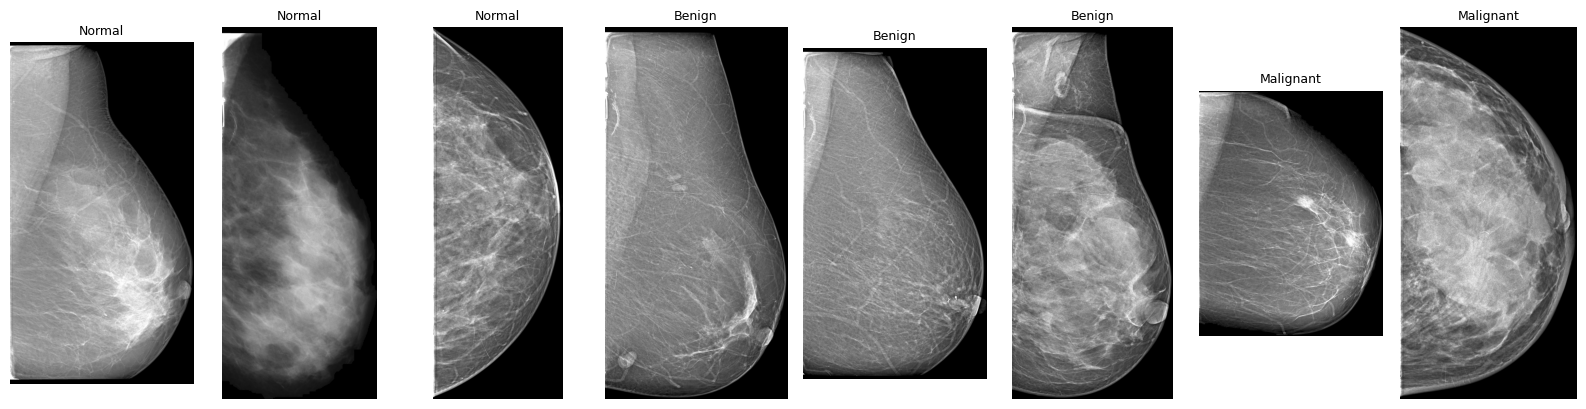

In [4]:
def breast_mask(g):
    s = 8
    small = cv2.resize(g, (g.shape[1] // s, g.shape[0] // s), interpolation=cv2.INTER_AREA)
    blur = cv2.GaussianBlur(small, (5, 5), 0)
    otsu = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[0]
    hist = np.bincount(blur.ravel(), minlength=256)[: max(2, int(otsu))].astype(np.float64)
    bg = int(np.convolve(hist, np.ones(5) / 5, mode="same").argmax())        # background level (not always 0)
    thr = bg + max(8.0, 0.35 * (otsu - bg))
    m = cv2.morphologyEx((blur > thr).astype(np.uint8), cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    if n <= 1:
        return np.ones_like(g, bool), bg
    m = (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)  # largest blob = breast; text = small blobs
    m = cv2.dilate(cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8)), np.ones((5, 5), np.uint8))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(m, cnts, -1, 1, thickness=cv2.FILLED)
    return cv2.resize(m, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_NEAREST).astype(bool), bg

def full_crop(sub, iid):
    # full-resolution breast crop: mask applied (burned-in text removed), per-image window, chest wall on the LEFT
    g = cv2.imread(str(DATA / sub / iid), cv2.IMREAD_GRAYSCALE)
    m, bg = breast_mask(g)
    ys, xs = np.where(m)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    hi = float(np.percentile(g[m][::16], 99.5))
    gn = np.clip((g.astype(np.float32) - bg) / max(hi - bg, 16.0), 0, 1) * 255.0
    out = np.where(m, gn, 0).astype(np.uint8)[y0:y1, x0:x1]
    mc = m[y0:y1, x0:x1]
    col = mc.sum(0).astype(np.float64); half = len(col) // 2
    flip = (mc[:, -8:].mean() - mc[:, :8].mean()) + 0.5 * (col[half:].sum() - col[:half].sum()) / (col.sum() + 1e-9) > 0
    if flip:
        out = out[:, ::-1]
    return np.ascontiguousarray(out), bool(flip), bg, float(m.sum())

def preprocess(job, long=2048):
    sub, iid = job
    out, flip, bg, area = full_crop(sub, iid)
    sc = long / max(out.shape)
    out = cv2.resize(out, (max(1, round(out.shape[1] * sc)), max(1, round(out.shape[0] * sc))), interpolation=cv2.INTER_AREA)
    cv2.imwrite(str(WORK / "img2048" / iid.replace(".jpg", ".png")), out)
    return dict(image_id=iid, flip=flip, bg=bg, area=area)

meta_path = WORK / "prep_meta.csv"
if meta_path.exists() and len(list((WORK / "img2048").glob("*.png"))) == len(train) + len(test):
    prep = pd.read_csv(meta_path)
else:
    jobs = [("train_images", i) for i in train.image_id] + [("test_images", i) for i in test.image_id]
    t0 = time.time()
    with ThreadPoolExecutor(6) as ex:
        prep = pd.DataFrame(list(ex.map(preprocess, jobs)))
    prep.to_csv(meta_path, index=False)
    print(f"preprocessed {len(prep)} images in {time.time() - t0:.0f}s")
print("grey-background exports:", int((prep.bg > 5).sum()), "| flipped:", int(prep.flip.sum()))

fig, axes = plt.subplots(1, 8, figsize=(16, 4.2))
for ax, (_, r) in zip(axes, train.groupby("label").head(3).sort_values("y").head(8).iterrows()):
    ax.imshow(cv2.imread(str(WORK / "img2048" / r.image_id.replace(".jpg", ".png")), 0), cmap="gray"); ax.set_title(r.label, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Struktur kasus: 2 citra per kasus, label sama
Paper sumber: 133 kasus / 266 citra. Pairing direkonstruksi **tanpa label** (OCR teks view dari citra mentah + kemiripan embedding 9 encoder [Mammo-FM, Mammo-CLIP B5/B2, RSNA-1st, mammoscreen, DINOv2] + sisi payudara + ukuran payudara + *max-weight perfect matching* di dalam tiap blok (split, mode) — kompetisi menyatakan test *patient-disjoint*); diaudit independen: dibangun ulang dengan label diacak → hasil identik byte-per-byte; **67/67 pasangan RGB train berlabel sama** (peluang acak 0.51). Hasilnya disimpan di `artifacts/pairs.csv` (kode pembuatnya: `experiments/tracks/pairs/`). Pairing bebas-label; fold di-stratifikasi dengan label (sah).

Beberapa wanita menyumbang dua kasus (kedua payudara) → fold CV di `artifacts/folds.csv` dikelompokkan **per wanita** (5 repeat × 5 fold). Dampaknya besar — probe yang sama pada fitur Mammo-CLIP B5: AUC **0.83** (fold per-citra, bocor) → 0.57 (per-kasus) → **0.52** (per-wanita); Mammo-FM: 0.84 → 0.65 → 0.61.

Jika `artifacts/pairs.csv` tidak ada, fallback: matcher sederhana (embedding Mammo-CLIP B5 + sisi payudara) — identik dengan pairing teraudit pada **test** (54/54), tetapi jauh lebih lemah pada train (~73% pasangan RGB), sehingga angka CV-nya kurang bisa dipercaya; fold lalu dikelompokkan per pasangan.

In [5]:
def fallback_pairs():
    # Simple label-free matcher: Mammo-CLIP B5 embedding similarity + same laterality, perfect matching per (split, mode).
    import networkx as nx
    from efficientnet_pytorch import EfficientNet
    ck = torch.load(WEIGHTS / "mammoclip" / "b5-model-best-epoch-7.tar", map_location="cpu", weights_only=False)["model"]
    net = EfficientNet.from_name("efficientnet-b5", num_classes=1)
    missing, unexpected = net.load_state_dict({k[len("image_encoder."):]: v for k, v in ck.items() if k.startswith("image_encoder.") and not k.startswith("image_encoder._fc")}, strict=False)
    assert not unexpected and all(m.startswith("_fc.") for m in missing), (missing[:3], unexpected[:3])
    net = net.eval().to(DEV).to(DT); net.set_swish(memory_efficient=False)
    ids = list(train.image_id) + list(test.image_id)
    E = []
    with torch.inference_mode():
        for iid in ids:
            x = torch.from_numpy(letterbox(iid, 1520, 912, center=False)).to(DEV).float()[None, None] / 255
            x = (((x - x.amin()) / (x.amax() - x.amin() + 1e-6) - 0.3089279) / 0.25053555).repeat(1, 3, 1, 1).to(DT)
            f = torch.stack([net.extract_features(v).mean((2, 3)) for v in (x, x.flip(2), x.flip(3))]).mean(0)
            E.append(f.float().cpu().numpy().ravel())
    E = np.stack(E)
    split = np.array([0] * len(train) + [1] * len(test)); isL = np.concatenate([train.is_L, test.is_L])
    side = prep.set_index("image_id").reindex(ids).flip.values.astype(int)
    mate = np.full(len(ids), -1)
    for sp in (0, 1):
        for L in (0, 1):
            rows = np.where((split == sp) & (isL == L))[0]
            Z = E[rows] / np.linalg.norm(E[rows], axis=1, keepdims=True); Z = (Z - Z.mean(0)) / (Z.std(0) + 1e-8)
            Z = Z / np.linalg.norm(Z, axis=1, keepdims=True); S = Z @ Z.T
            G = nx.Graph()
            for a in range(len(rows)):
                for b in range(a + 1, len(rows)):
                    G.add_edge(a, b, weight=S[a, b] - 0.5 * (side[rows[a]] != side[rows[b]]) + 10.0)
            for a, b in nx.max_weight_matching(G, maxcardinality=True):
                mate[rows[a]], mate[rows[b]] = rows[b], rows[a]
    assert (mate >= 0).all(), "odd-sized (split, mode) block: an image has no mate"
    pid = np.full(len(ids), -1); c = 0
    for i in range(len(ids)):
        if pid[i] < 0:
            pid[i] = c; pid[mate[i]] = c; c += 1
    return pd.DataFrame(dict(image_id=ids, pair_id=pid))

def letterbox(iid, H, W, center=True):
    # aspect-preserving fit + zero padding (RSNA-1st validation transform: centred)
    g = cv2.imread(str(WORK / "img2048" / iid.replace(".jpg", ".png")), 0)
    sc = min(H / g.shape[0], W / g.shape[1])
    g = cv2.resize(g, (max(1, round(g.shape[1] * sc)), max(1, round(g.shape[0] * sc))), interpolation=cv2.INTER_AREA)
    c = np.zeros((H, W), np.uint8)
    y0, x0 = (H - g.shape[0]) // 2, ((W - g.shape[1]) // 2 if center else 0)
    c[y0:y0 + g.shape[0], x0:x0 + g.shape[1]] = g
    return c

AUDITED = (ART / "pairs.csv").exists()
pairs = pd.read_csv(ART / "pairs.csv") if AUDITED else fallback_pairs()
if "view" not in pairs:
    pairs["view"] = "?"       # view text (CC / MLO / ML) only fixes the slot order of the two-view LSTM models
pairs = pairs[["image_id", "pair_id", "view"]]
train = train.merge(pairs, on="image_id", how="left", validate="one_to_one"); test = test.merge(pairs, on="image_id", how="left", validate="one_to_one")
assert list(train.image_id) == list(pd.read_csv(DATA / "train.csv").image_id) and list(test.image_id) == list(pd.read_csv(DATA / "test.csv").image_id), "row order changed"
assert train.pair_id.notna().all() and test.pair_id.notna().all()
assert not set(train.pair_id) & set(test.pair_id), "a case spans train and test"
g = train.groupby("pair_id")
print("train cases:", g.ngroups, "| images per case:", g.size().value_counts().to_dict(), "| test cases:", test.pair_id.nunique())
print("VALIDATION (labels used only here): cases whose images share one label = %d/%d | RGB cases: %d/%d" % (
    (g.label.nunique() == 1).sum(), g.ngroups, (g.label.nunique()[g.is_L.first() == 0] == 1).sum(), (g.is_L.first() == 0).sum()))
print("cases mixing L/RGB files:", int((g.is_L.nunique() > 1).sum()), "| test RGB cases:", test[test.is_L == 0].pair_id.nunique())

if AUDITED and (ART / "folds.csv").exists():   # the woman-grouped folds belong to the audited pairing
    F = train[["image_id"]].merge(pd.read_csv(ART / "folds.csv"), on="image_id", how="left", validate="one_to_one").filter(like="rep").values
    assert not np.isnan(F.astype(float)).any(), "a training image has no fold"
    F = F.astype(int)
else:   # pair-grouped fallback (weaker than woman-grouped: reads ~0.02-0.03 AUC optimistic)
    up = train.groupby("pair_id").y.first()
    F = np.zeros((len(train), 5), int)
    for r in range(5):
        for k, (_, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED + r).split(up.index, up.values)):
            F[train.pair_id.isin(up.index[va]).values, r] = k
assert all(train.assign(f=F[:, r]).groupby("pair_id").f.nunique().max() == 1 for r in range(F.shape[1])), "a case is split across folds"
print("folds:", F.shape, "| rep0 fold x class:", pd.crosstab(F[:, 0], train.label).values.tolist())

train cases: 106 | images per case: {2: 106} | test cases: 27
VALIDATION (labels used only here): cases whose images share one label = 106/106 | RGB cases: 67/67
cases mixing L/RGB files: 0 | test RGB cases: 17
folds: (212, 5) | rep0 fold x class: [[12, 18, 16], [10, 16, 14], [10, 14, 16], [10, 16, 18], [10, 16, 16]]


## 5. Skor zero-shot — keluarga 1: ConvNeXt-small juara-1 RSNA 2023 (beku)
Untuk tiap fold checkpoint & skala: **logit kanker zero-shot** dan fitur *pooled* 1536-d (fitur hanya dipakai untuk varian *image-only*), dirata-rata atas 4 *view* TTA. Hasil di-*cache* ke `nb_cache/feats/`.

Satu job GPU pada satu waktu + *thermal guard* (laptop GPU: jeda bila ≥ 84 °C).

In [6]:
def gpu_temp():
    try:
        return int(subprocess.check_output(["nvidia-smi", "--query-gpu=temperature.gpu", "--format=csv,noheader"], text=True).split()[0])
    except Exception:
        return -1

def cool_down(hot=84, ok=76):
    if gpu_temp() >= hot:
        while gpu_temp() > ok:
            time.sleep(10)

def kaggle_file(ref, file, dst_dir):
    # download ONE file of a public Kaggle dataset (needs the Kaggle CLI + ~/.kaggle/kaggle.json); returns the local path
    dst_dir = Path(dst_dir); p = dst_dir / Path(file).name
    if not p.exists():
        dst_dir.mkdir(parents=True, exist_ok=True)
        try:
            subprocess.run(["kaggle", "datasets", "download", ref, "-f", file, "-p", str(dst_dir)], check=True)
        except Exception as e:
            raise RuntimeError(f"Download '{file}' manually from https://www.kaggle.com/datasets/{ref} into {dst_dir}") from e
        for z in dst_dir.glob("*.zip"):
            import zipfile; zipfile.ZipFile(z).extractall(dst_dir); z.unlink()
    return p

def load_rsna(k):
    m = timm.create_model("convnext_small.fb_in22k_ft_in1k_384", pretrained=False, num_classes=1, in_chans=3, global_pool="max")
    path = kaggle_file("dangnh0611/rsna-breast-cancer-detection-best-ckpts", f"best_convnext_fold_{k}.pth.tar", WEIGHTS / "rsna1st")
    ck = torch.load(path, map_location="cpu", weights_only=False)   # official 1st-place checkpoint (pickle)
    sd = ck.get("state_dict_ema") or ck.get("state_dict", ck)
    m.load_state_dict({q.replace("module.", ""): v for q, v in sd.items()}, strict=True)
    return m.eval().to(DEV).to(DT)

MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEV).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.229, 0.224, 0.225], device=DEV).view(1, 3, 1, 1) * 255

@torch.inference_mode()
def rsna_forward(m, img):
    x = torch.from_numpy(img).to(DEV).float()[None, None]
    fs, ls = [], []
    for v in (x, x.flip(2), x.flip(3), x.flip(2).flip(3)):
        fm = m.forward_features(((v.repeat(1, 3, 1, 1) - MEAN) / STD).to(DT))
        pre = m.forward_head(fm, pre_logits=True)
        fs.append(torch.cat([pre, fm.mean((2, 3))], 1).float()); ls.append(m.head.fc(pre)[:, 0].float().sigmoid())
    p = torch.stack(ls).mean().clamp(1e-6, 1 - 1e-6)
    return torch.stack(fs).mean(0).cpu().numpy().ravel(), float(torch.log(p / (1 - p)))

def rsna_cache(k, H, W):
    return WORK / "feats" / f"rsna1st_f{k}_{H}x{W}.npz"

ids_all = list(train.image_id) + list(test.image_id)
for k in RSNA_FOLDS:
    todo = [(H, W) for (H, W) in sorted(set(ZS_SCALES + [HEAD_SCALE])) if not rsna_cache(k, H, W).exists()]
    if not todo:
        continue
    model = load_rsna(k)
    for (H, W) in todo:
        t0 = time.time(); feats, logits = [], []
        for n, iid in enumerate(ids_all):
            f, l = rsna_forward(model, letterbox(iid, H, W)); feats.append(f); logits.append(l)
            if n % 5 == 4:
                cool_down()
        feats, logits = np.stack(feats), np.array(logits, np.float32)
        tmp = rsna_cache(k, H, W).with_suffix(".tmp.npz")          # atomic write: a crash can never leave a truncated cache file
        np.savez_compressed(tmp, ids=np.array(ids_all), train=feats[:len(train)], test=feats[len(train):], train_logit=logits[:len(train)], test_logit=logits[len(train):])
        os.replace(tmp, rsna_cache(k, H, W))
        print(f"fold {k} @ {H}x{W}: {time.time() - t0:.0f}s, gpu {gpu_temp()}C", flush=True)
    del model; torch.cuda.empty_cache(); time.sleep(20)

RS = {}
for k in RSNA_FOLDS:
    for (H, W) in sorted(set(ZS_SCALES + [HEAD_SCALE])):
        with np.load(rsna_cache(k, H, W)) as d:                     # eager load, file handle released
            RS[(k, H, W)] = {n: d[n] for n in d.files}
        r = RS[(k, H, W)]
        assert r["train"].shape[0] == len(train) and r["test"].shape[0] == len(test) and np.isfinite(r["train"]).all() and np.isfinite(r["test"]).all()
        assert list(r["ids"]) == ids_all, "stale feature cache: image list changed"
print("RSNA-1st cached feature files:", len(RS))

RSNA-1st cached feature files: 12


## 6. Skor zero-shot — tim 2 & 3: juara-3 RSNA 2023 & Theo Viel
Data latih eksternal kedua tim ini memberi label **lesi jinak = negatif** (CBIS-DDSM, CMMD, Mini-DDSM) dan VinDr **BI-RADS 4–5 = positif vs 2–3 = negatif** — mirip definisi Benign/Malignant dataset ini.

| tim | keluarga | arsitektur | input | level |
|---|---|---|---|---|
| juara-3 | `rsna3rd_fw` (4 fold) | EfficientNetV2-S, 1 kanal | 2048×1280 | citra |
| juara-3 | `rsna3rd_kv_a`, `rsna3rd_kv_b`, `rsna3rd_kv_c` | ConvNeXt-nano ×2, EfficientNetV2-S (anggota blend final juara-3) | 1536×960 | citra |
| juara-3 | `rsna3rd_bo_cnt`, `rsna3rd_bo_v2s` (5 fold) | ConvNeXt-tiny / EffNetV2-S **+ BiLSTM** atas slot [CC, MLO, CC, MLO] | 1280×800 | **kasus** |
| Theo Viel | 5 run: EffNetV2-M ×2, ECA-NFNet-L2 ×2, ECA-NFNet-L1 | + GeM | 1536×1024 | citra |

Input = PNG hasil preprocessing bagian 3 (sudah di-*window* per-citra), `/255` tanpa normalisasi mean/std; model juara-3 di-*pad* nol ke rasio H:W-nya (pendekatan dari crop YOLOX asli mereka), model Theo di-*stretch* ke 1536×1024 (sesuai `config.json` Theo: `img_folder yolox_1536_1024`, `window False`, `use_gem True`); TTA flip horizontal. Skor = logit kanker; **tidak ada yang dilatih di data ini**. Head aux Theo tidak dipakai (targetnya tidak terdokumentasi). Cache skor berasal dari run eksperimen (`experiments/29_*.py`, `30_*.py`, `scorers/team_extra.py`); yang dihitung ulang oleh notebook identik bit-per-bit dengannya.

In [7]:
import torch.nn as nn

class TimmLSTM(nn.Module):
    # 3rd-place breast-level model (Bo Liu): shared 1-channel CNN over 4 image slots -> 2-layer BiLSTM -> per-slot cancer logit
    def __init__(self, backbone):
        super().__init__()
        self.encoder = timm.create_model(backbone, in_chans=1, num_classes=1, pretrained=False)
        if "efficient" in backbone:
            hdim = self.encoder.conv_head.out_channels; self.encoder.classifier = nn.Identity()
        else:
            hdim = self.encoder.head.fc.in_features; self.encoder.head.fc = nn.Identity()
        self.lstm = nn.LSTM(hdim, 256, num_layers=2, dropout=0, bidirectional=True, batch_first=True)
        self.head = nn.Sequential(nn.Linear(512, 256), nn.BatchNorm1d(256), nn.Dropout(0), nn.LeakyReLU(0.1), nn.Linear(256, 1))
    def forward(self, x):                                   # (B, 4, 1, H, W) in [0, 1]
        b = x.shape[0]
        f, _ = self.lstm(self.encoder(x.view(b * 4, 1, *x.shape[-2:])).view(b, 4, -1))
        return self.head(f.contiguous().view(b * 4, 512)).view(b, -1)

class TheoCls(nn.Module):
    # Theo Viel's classifier: timm encoder -> GeM(p=3) -> cancer logit (+ an auxiliary head we do not use)
    def __init__(self, name):
        super().__init__()
        self.encoder = timm.create_model(name, pretrained=False, num_classes=0, global_pool="")
        self.logits = nn.Linear(self.encoder.num_features, 1); self.logits_aux = nn.Linear(self.encoder.num_features, 3)
    def forward(self, x):
        f = self.encoder.forward_features(x).clamp(min=1e-6).pow(3).mean((-1, -2)).pow(1 / 3)
        return self.logits(f)

class Config_YAML(dict):            # the 3rd-place Lightning checkpoints pickle their hparams as __main__.Config_YAML
    pass
sys.modules["__main__"].Config_YAML = Config_YAML

def lightning_backbone(path, arch):
    sd = torch.load(path, map_location="cpu", weights_only=False)["state_dict"]
    sd = {q[len("backbone."):]: v for q, v in sd.items() if q.startswith("backbone.")}
    first = next(v for q, v in sd.items() if v.ndim == 4)                    # stem conv -> number of input channels
    m = timm.create_model(arch, pretrained=False, in_chans=first.shape[1], num_classes=1)
    m.load_state_dict(sd, strict=True)
    return m, first.shape[1]

def pad_to(g, H, W, vpad):
    # zero-pad the breast crop (chest wall on the left) to aspect H:W - extra width on the nipple side, extra height on top / centred
    h, w = g.shape
    if h / w > H / W:
        c = np.zeros((h, int(round(h * W / H))), np.uint8); c[:, :w] = g
    else:
        nh = int(round(w * H / W)); c = np.zeros((nh, w), np.uint8)
        y0 = nh - h if vpad == "top" else (nh - h) // 2
        c[y0:y0 + h] = g
    return cv2.resize(c, (W, H), interpolation=cv2.INTER_LINEAR)

def crop(iid):
    return cv2.imread(str(WORK / "img2048" / iid.replace(".jpg", ".png")), 0)

B3 = "boliu0/convnt-lstm-1280x800pos3x-20ep-4ext-savebysite-yol"; B3V = "boliu0/v2s-lstm-1280x800pos3x-20ep-4ext-savebysite-5e6"
SCORERS = {}   # name -> (kind, kaggle ref, file in the dataset, arch, (H, W), vpad)
for k, f in enumerate(["0/epoch08-val_pF10.4055-threshold0.5800.ckpt", "1/epoch07-val_pF10.4531-threshold0.4900.ckpt",
                       "2/epoch09-val_pF10.3943-threshold0.5200.ckpt", "3/epoch06-val_pF10.3692-threshold0.7500.ckpt"]):
    SCORERS[f"rsna3rd_fw_f{k}"] = ("image", "forcewithme/rsna0128weights", "effv2s_2048-1280_4ext/" + f, "tf_efficientnetv2_s", (2048, 1280), "center")
SCORERS["rsna3rd_kv_a"] = ("image", "kevin1742064161/convnext-nano-1536960-mix0-4ex-yolox", "convnext_nano_1536960_mix0_4ex_yolox/1/epoch12-patient_val_pF10.5579-threshold0.4700.ckpt", "convnext_nano", (1536, 960), "top")
SCORERS["rsna3rd_kv_b"] = ("image", "kevin1742064161/convnext-1536960-mix0-4ex-yoloxnano", "convnext_1536960_mix0_4ex_yoloxnano/3/epoch10-patient_val_pF10.4938-threshold0.3200.ckpt", "convnext_nano", (1536, 960), "top")
for k in range(5):
    SCORERS[f"rsna3rd_bo_cnt_f{k}"] = ("lstm", B3, f"convnt_lstm_1280x800pos3x_20ep_4ext_savebysite_yolox_fold{k}_best.pth", "convnext_tiny.fb_in22k_ft_in1k_384", (1280, 800), "center")
    SCORERS[f"rsna3rd_bo_v2s_f{k}"] = ("lstm", B3V, f"v2s_lstm_1280x800pos3x_20ep_4ext_savebysite_5e6_fold{k}_best.pth", "tf_efficientnetv2_s.in21k_ft_in1k", (1280, 800), "center")
SCORERS["theo_tf_efficientnetv2_m"] = ("theo", "theoviel/rsna-breast-weights-4", "2023-02-12_2/tf_efficientnetv2_m_fullfit_0.pt", "tf_efficientnetv2_m", (1536, 1024), "stretch")
SCORERS["theo_eca_nfnet_l2"] = ("theo", "theoviel/rsna-breast-weights-4", "2023-02-12_1/eca_nfnet_l2_fullfit_0.pt", "eca_nfnet_l2", (1536, 1024), "stretch")
SCORERS["rsna3rd_kv_c"] = ("image", "kevin1742064161/effnetv2-1536960-mix3-2ex-yolox", "effnetv2_1536960_mix3_2ex_yolox/0/epoch11-patient_val_pF10.5073-threshold0.4100.ckpt", "tf_efficientnetv2_s", (1536, 960), "top")
SCORERS["theo_eca_nfnet_l2_noaux"] = ("theo", "theoviel/rsna-breast-weights-4", "2023-02-19_2/eca_nfnet_l2_fullfit_0.pt", "eca_nfnet_l2", (1536, 1024), "stretch")
SCORERS["theo_eca_nfnet_l1"] = ("theo", "theoviel/rsna-breast-weights-4", "2023-02-13_15/eca_nfnet_l1_fullfit_0.pt", "eca_nfnet_l1", (1536, 1024), "stretch")
SCORERS["theo_tf_efficientnetv2_m_0210"] = ("theo", "theoviel/rsna-breast-weights-3", "2023-02-10_16/tf_efficientnetv2_m_fullfit_0.pt", "tf_efficientnetv2_m", (1536, 1024), "stretch")

def to_logit(p):
    p = min(max(p, 1e-6), 1 - 1e-6); return math.log(p / (1 - p))

pid_all = np.concatenate([train.pair_id.values, test.pair_id.values]); view_all = np.concatenate([train["view"].values, test["view"].values])
(WORK / "scores").mkdir(exist_ok=True)

@torch.inference_mode()
def run_scorer(name):
    kind, ref, file, arch, (H, W), vpad = SCORERS[name]
    path = kaggle_file(ref, file, WEIGHTS / "zoo" / name)
    if kind == "image":
        m, nch = lightning_backbone(path, arch)
    elif kind == "theo":
        m, nch = TheoCls(arch), 3
        r = m.load_state_dict(torch.load(path, map_location="cpu", weights_only=False), strict=False)
        assert not [k for k in r.missing_keys if not k.startswith("logits_aux")], r.missing_keys[:3]           # some runs have no aux head
        assert not [k for k in r.unexpected_keys if not k.startswith(("encoder.classifier", "encoder.head.fc"))], r.unexpected_keys[:3]  # older runs keep the ImageNet head
    else:
        sd = torch.load(path, map_location="cpu", weights_only=False); sd = sd.get("model_state_dict", sd)
        m = TimmLSTM(arch); m.load_state_dict({(q[7:] if q.startswith("module.") else q): v for q, v in sd.items()}, strict=True)
    m = m.eval().to(DEV)
    prep = lambda iid: (cv2.resize(crop(iid), (W, H), interpolation=cv2.INTER_LINEAR) if vpad == "stretch" else pad_to(crop(iid), H, W, vpad)).astype(np.float32) / 255.0
    s = np.zeros(len(ids_all), np.float32)
    ac = lambda: torch.autocast("cuda", dtype=torch.float16) if DEV == "cuda" else torch.autocast("cpu", enabled=False)
    if kind == "lstm":                                                        # one forward per CASE: slots [CC, MLO, CC, MLO]
        for n, c in enumerate(np.unique(pid_all)):
            idx = sorted(np.where(pid_all == c)[0], key=lambda j: 0 if view_all[j] == "CC" else 1)
            x = torch.from_numpy(np.stack([prep(ids_all[j]) for j in (idx * 2)[:4]])).to(DEV)[None, :, None]
            with ac():
                p = torch.stack([m(v).float().sigmoid()[0, :2].mean() for v in (x, x.flip(-1))]).mean().item()
            s[idx] = to_logit(p)
            if n % 5 == 4: cool_down()
    else:
        for n, iid in enumerate(ids_all):
            x = torch.from_numpy(prep(iid)).to(DEV)[None, None].repeat(1, nch, 1, 1)
            with ac():
                p = torch.stack([m(v).float().sigmoid().reshape(-1)[0] for v in (x, x.flip(-1))]).mean().item()
            s[n] = to_logit(p)
            if n % 5 == 4: cool_down()
    del m; torch.cuda.empty_cache()
    return s

SC = {}
for name in SCORERS:
    cache = WORK / "scores" / f"{name}.npz"
    if not cache.exists():
        t0 = time.time(); s = run_scorer(name); assert np.isfinite(s).all()
        tmp = cache.with_suffix(".tmp.npz"); np.savez_compressed(tmp, ids=np.array(ids_all), train=s[:len(train)], test=s[len(train):]); os.replace(tmp, cache)
        print(f"{name}: {time.time() - t0:.0f}s, gpu {gpu_temp()}C", flush=True); time.sleep(15)
    with np.load(cache) as d:
        assert list(d["ids"]) == ids_all, "stale score cache"
        SC[name] = (d["train"].astype(np.float64), d["test"].astype(np.float64))
print("zero-shot score files:", len(SC))

zero-shot score files: 22


## 6b. Skor zero-shot — tim 4: MAM-CLIP, pengklasifikasi **BI-RADS**
MAM-CLIP (Gulluk & Gevaert; kode `github.com/igulluk/MAM-CLIP`, bobot di folder Google Drive yang ditautkan README-nya) melatih *head* **BI-RADS {0, 1, 2, 4, 5}** di atas ConvNeXt-Small/Tiny pada data skrining nasional Turki (TEKNOFEST 2023 / MammosighTR) berlabel **impresi BI-RADS radiolog tanpa biopsi** — persis jenis label dataset ini, dan sepenuhnya independen dari RSNA. Skor = logit P(BI-RADS 4 atau 5).

Port (dari kode asli, `experiments/scorers/mamclip.py`): crop payudara resolusi penuh dalam **orientasi natural** DICOM (payudara kanan dikembalikan ke dinding dada di kanan, seperti PNG TEKNOFEST yang dirilis), `resize_and_pad` ke 1024×768 (pertahankan rasio, bilinear, *pad* nol di tengah), 3 kanal, min-max ke [0,1] tanpa mean/std, TTA flip horizontal. Urutan kelas head tidak tertulis di rilis → diverifikasi pada **data sumber model sendiri** (120 citra publik MammosighTR, bukan data kita): permutasi identitas, AUC {4,5} vs {1,2} = 1.00.

**Adaptasi intensitas tanpa label** (ditetapkan sebelum evaluasi): citra CR kita jauh lebih terang daripada input TEKNOFEST (median piksel payudara 0.54 vs 0.27 setelah min-max) → selain input asli, piksel payudara dicocokkan histogramnya ke distribusi gabungan 120 citra referensi TEKNOFEST (`artifacts/tekno_ref/`, CC BY-NC 4.0); skor MAM-CLIP = rata-rata logit kedua input (TTA intensitas).

In [8]:
import torch.nn.functional as TF

MAMCLIP_DRIVE = {"small": ("convnext_small", "1MHMaYD-F3Vk05sCh0J3OOWGAa1-j57ES", 200347354),
                 "tiny": ("convnext_tiny", "1AduR91COdEtDS4D55ZxkdRFmwW_x6nPA", 113744038)}
TEKNO_REF = ART / "tekno_ref"
SUB = {i: "train_images" for i in train.image_id} | {i: "test_images" for i in test.image_id}

def gdrive_file(fid, dst, size):
    dst = Path(dst)
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        try:
            subprocess.run(["curl", "-L", "-s", "-S", "-A", "Mozilla/5.0", "-o", str(dst), f"https://drive.usercontent.google.com/download?id={fid}&export=download&confirm=t"], check=True)
        except Exception as e:
            raise RuntimeError(f"Download {dst.name} manually (Google Drive id {fid}, linked from github.com/igulluk/MAM-CLIP) into {dst.parent}") from e
    assert dst.stat().st_size == size, f"{dst} has {dst.stat().st_size} bytes, expected {size}"
    return dst

def load_mamclip(a):
    arch, fid, size = MAMCLIP_DRIVE[a]
    m = timm.create_model(arch, pretrained=False)                 # the authors' loader (train/mam_clip_load.ipynb)
    m.head.fc = nn.Linear(768, 768); m.birads_layer = nn.Sequential(nn.Linear(768, 5)); m.density_layer = nn.Sequential(nn.Linear(768, 4))
    m.load_state_dict(torch.load(gdrive_file(fid, WEIGHTS / "mamclip" / f"{arch}_ftune.pth", size), map_location="cpu", weights_only=True), strict=True)
    return m.eval().to(DEV)

def natural_view(iid):
    out, flip, _, _ = full_crop(SUB[iid], iid)                     # chest wall on the left ...
    return np.ascontiguousarray(out[:, ::-1]) if flip else out    # ... back to the natural DICOM orientation

def resize_and_pad(img, hw=(1024, 768)):                          # dangnh0611 submit.py resize_and_pad (the MAM-CLIP crop pipeline)
    t = torch.from_numpy(np.ascontiguousarray(img, dtype=np.float32)); h, w = t.shape
    t = TF.interpolate(t.view(1, 1, h, w), mode="bilinear", scale_factor=min(hw[0] / h, hw[1] / w), recompute_scale_factor=True)[0, 0]
    out = torch.zeros(hw, dtype=t.dtype); ch, cw = t.shape; y0, x0 = (hw[0] - ch) // 2, (hw[1] - cw) // 2
    out[y0:y0 + ch, x0:x0 + cw] = t
    return out.to(torch.uint8).numpy()

def tekno_quantiles(n=1001):
    v = np.concatenate([g[g > 8] for g in (cv2.imread(str(f), 0) for f in sorted(TEKNO_REF.glob("*.jpg")))]).astype(np.float32)   # > 8: JPEG background noise
    return np.quantile(v, np.linspace(0, 1, n))

def hist_match(png, refq):
    out = png.astype(np.float32).copy(); msk = png > 0; v = png[msk].astype(np.float32)
    ranks = (np.argsort(np.argsort(v, kind="stable"), kind="stable") + 0.5) / len(v)
    out[msk] = np.interp(ranks, np.linspace(0, 1, len(refq)), refq)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

@torch.inference_mode()
def birads45_logit(model, png):
    x = np.stack([png] * 3).astype(np.float32); x -= x.min(); x /= max(float(x.max()), 1e-6)
    x = torch.from_numpy(x); xb = torch.stack([x, x.flip(2)]).to(DEV)                          # natural + horizontal mirror
    p = model.birads_layer(model(xb)).float().softmax(1).mean(0).cpu().numpy().astype(np.float64)  # classes [BI-RADS 0, 1, 2, 4, 5]
    q = float(np.clip(p[3] + p[4], 1e-7, 1 - 1e-7))
    return math.log(q) - math.log1p(-q)

MAM_NAMES = [f"mamclip_{a}_birads45{v}" for a in MAMCLIP_DRIVE for v in ("", "hm")]
if not all((WORK / "scores" / f"{n}.npz").exists() for n in MAM_NAMES):
    assert len(list(TEKNO_REF.glob("*.jpg"))) >= 100, "artifacts/tekno_ref/ (TEKNOFEST reference images) is missing"
    refq = tekno_quantiles(); models = {a: load_mamclip(a) for a in MAMCLIP_DRIVE}
    res = {n: np.zeros(len(ids_all)) for n in MAM_NAMES}; t0 = time.time()
    for n, iid in enumerate(ids_all):
        png = resize_and_pad(natural_view(iid)); png_m = hist_match(png, refq)
        for a, m in models.items():
            res[f"mamclip_{a}_birads45"][n] = birads45_logit(m, png)
            res[f"mamclip_{a}_birads45hm"][n] = birads45_logit(m, png_m)
        if n % 5 == 4: cool_down()
    for name, s in res.items():
        cache = WORK / "scores" / f"{name}.npz"; tmp = cache.with_suffix(".tmp.npz")
        np.savez_compressed(tmp, ids=np.array(ids_all), train=s[:len(train)], test=s[len(train):]); os.replace(tmp, cache)
    del models; torch.cuda.empty_cache()
    print(f"MAM-CLIP: {time.time() - t0:.0f}s, gpu {gpu_temp()}C")
for name in MAM_NAMES:
    with np.load(WORK / "scores" / f"{name}.npz") as d:
        assert list(d["ids"]) == ids_all, "stale score cache"
        SC[name] = (d["train"].astype(np.float64), d["test"].astype(np.float64))
print("zero-shot score files:", len(SC))

zero-shot score files: 26


## 6c. Skor zero-shot — tim 5: Mergen1 (TEKNOFEST 2023), pengklasifikasi **BI-RADS**
EfficientNet-B0 3 kelas **[BI-RADS 0, BI-RADS 1–2, BI-RADS 4–5]** dari tim finalis TEKNOFEST 2023 "Sağlıkta Yapay Zeka" (kode `github.com/uraninjo/Mergen1-Teknofest-Mammography-Classification`, bobot di folder Google Drive yang ditautkan README). Dilatih pada ~27 ribu citra skrining Turki berlabel BI-RADS radiolog — independen dari RSNA dan dari MAM-CLIP. Skor = logit P(BI-RADS 4–5).

Port (dari notebook tim, `experiments/scorers/mergen1_effb0_birads.py`): crop payudara bertopeng dalam **orientasi natural**, diskalakan dengan **maksimum crop** (seperti `plt.imsave(cmap='gray')` mereka) — plus varian yang maksimumnya dibatasi 1.5 × persentil 99.5 (label-free, untuk piksel jenuh pada citra CR kita), `Resize((500, 250))` PIL bilinear, `[0,1]` tanpa mean/std, TTA flip horizontal. Keputusan "tanpa Normalize" dan urutan kelas diverifikasi pada data sumber model sendiri (120 citra MammosighTR publik: AUC {4,5} vs {1,2} = 0.96 dengan `[0,1]`, 0.53 dengan normalisasi ImageNet).

In [9]:
MERGEN1 = ("15xzemF_RusjEBXX8fc6dVAZ7u8HIpQFE", 16391309)      # Drive id, bytes of BIRADS_EfficientNetb0_0.7095acc.h5 (a torch.save zip)

def load_mergen1():
    sd_path = WEIGHTS / "mergen1_effb0_birads" / "effb0_birads3_state_dict.pth"
    if not sd_path.exists():   # the release is a pickled nn.Module (scanned: torch / torchvision globals only) -> keep only the state_dict
        src = gdrive_file(MERGEN1[0], WEIGHTS / "mergen1_effb0_birads" / "BIRADS_EfficientNetb0_0.7095acc.h5", MERGEN1[1])
        torch.save(torch.load(src, map_location="cpu", weights_only=False).state_dict(), sd_path)
    m = torchvision.models.efficientnet_b0(num_classes=3)
    m.load_state_dict(torch.load(sd_path, map_location="cpu", weights_only=True), strict=True)
    return m.eval().to(DEV)

def mergen_png(iid, cap=None):
    # masked tight breast crop in the ORIGINAL (natural) orientation, scaled by the crop maximum (optionally capped)
    g = cv2.imread(str(DATA / SUB[iid] / iid), cv2.IMREAD_GRAYSCALE)
    m, bg = breast_mask(g)
    ys, xs = np.where(m)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    v = np.clip(g.astype(np.float32) - bg, 0, None)
    hi = float(v[m].max())
    if cap is not None:
        hi = min(hi, cap * float(np.percentile(v[m][::4], 99.5)))
    x = np.where(m, np.clip(v / max(hi, 16.0), 0, 1), 0)[y0:y1, x0:x1]
    return np.ascontiguousarray(np.clip(np.floor(x * 256), 0, 255).astype(np.uint8))

@torch.inference_mode()
def mergen_logit(model, u8):
    r = np.asarray(Image.fromarray(u8).resize((250, 500), Image.BILINEAR), np.float32) / 255.0
    x = torch.from_numpy(np.stack([r, r, r]))
    p = model(torch.stack([x, x.flip(2)]).to(DEV)).float().softmax(1).mean(0).cpu().numpy().astype(np.float64)   # [BI-RADS0, 1-2, 4-5]
    q = float(np.clip(p[2], 1e-7, 1 - 1e-7))
    return math.log(q) - math.log1p(-q)

MERGEN_NAMES = {"mergen1_effb0_birads45": None, "mergen1_effb0cap_birads45": 1.5}
if not all((WORK / "scores" / f"{n}.npz").exists() for n in MERGEN_NAMES):
    model = load_mergen1(); res = {n: np.zeros(len(ids_all)) for n in MERGEN_NAMES}; t0 = time.time()
    for n, iid in enumerate(ids_all):
        for name, cap in MERGEN_NAMES.items():
            res[name][n] = mergen_logit(model, mergen_png(iid, cap))
        if n % 10 == 9: cool_down()
    for name, s in res.items():
        cache = WORK / "scores" / f"{name}.npz"; tmp = cache.with_suffix(".tmp.npz")
        np.savez_compressed(tmp, ids=np.array(ids_all), train=s[:len(train)], test=s[len(train):]); os.replace(tmp, cache)
    del model; torch.cuda.empty_cache()
    print(f"Mergen1: {time.time() - t0:.0f}s")
for name in MERGEN_NAMES:
    with np.load(WORK / "scores" / f"{name}.npz") as d:
        assert list(d["ids"]) == ids_all, "stale score cache"
        SC[name] = (d["train"].astype(np.float64), d["test"].astype(np.float64))
print("zero-shot score files:", len(SC))

zero-shot score files: 28


## 7. Ensemble tim & evaluasi (CV aman-per-wanita, keputusan per kasus)
1. **Keluarga** = satu model dari sebuah solusi publik; fold/skalanya (dan untuk MAM-CLIP: input asli + input yang dicocokkan histogramnya) dirata-rata dulu (logit).
2. Dua view satu kasus dirata-rata → z-score per keluarga atas semua kasus RGB (train + test, **tanpa label**) → skor **tim** = rata-rata keluarganya → skor akhir = rata-rata **bobot sama per tim** (juara-1 RSNA, juara-3 RSNA, Theo Viel, MAM-CLIP, Mergen1). Tidak ada bobot yang di-fit ke label.
3. Platt *class-balanced* 2-parameter (di-fit **di dalam fold train**) → **P(M) > 0.5 ⇒ Malignant**; kedua citra satu kasus berlabel sama.

**Seleksi tim (dicatat jujur, `experiments/PREREGISTRATION_v3.md`).** Tiga belas model/tim publik diskor tanpa melihat label: RSNA 2023 juara-1…6, Theo Viel, NYU GMIC, dpetrini (CBIS), MAM-CLIP (head BI-RADS dan VLM zero-shot teks), Mergen1, MedSigLIP-VinDr. Aturan yang dipra-registrasi lebih dulu — *semua* tim bobot sama — memberi AUC kasus hanya **0.78**, karena sebagian besar mentransfer buruk ke data CR ini (0.50–0.69). Aturan sekunder yang juga dipra-registrasi — simpan tim yang AUC-nya dalam 0.10 dari yang terbaik — memilih lima tim di atas; karena pemilihan ini melihat label, nilainya diperkirakan **out-of-bag** (tim dipilih pada sampel bootstrap, dinilai pada kasus di luar sampel): **≈ 0.82** — itulah angka yang jujur, bukan AUC in-sample di tabel. Stacking dengan meta-learner logistic regression (ala Ali dkk., *Diagnostics* 2023) juga diuji di dalam fold: tidak lebih baik dari bobot sama (macro-F1 0.824 vs 0.821).

In [10]:
y = train.y.values
ab = y > 0                                   # abnormal (Benign / Malignant) training images
ptr, pte = train.pair_id.values, test.pair_id.values
rgb_tr, rgb_te = train.is_L.values == 0, test.is_L.values == 0
sg = lambda s: 1 / (1 + np.exp(-s))

def case_mean(A, g):
    A = np.asarray(A, np.float64)
    return pd.DataFrame(A.reshape(len(A), -1)).groupby(np.asarray(g)).transform("mean").values.reshape(A.shape)

def platt(s_fit, y_fit, s_new):
    m = LogisticRegression(C=1e3, class_weight="balanced", max_iter=1000).fit(np.asarray(s_fit)[:, None], y_fit)
    return sg(max(float(m.coef_[0, 0]), 1e-3) * np.asarray(s_new) + float(m.intercept_[0]))

# ---- families (folds / scales / intensity-TTA inputs of one model are averaged first) -> teams
members = {"rsna1st": [(RS[(k, H, W)]["train_logit"], RS[(k, H, W)]["test_logit"]) for k in RSNA_FOLDS for (H, W) in ZS_SCALES]}
for name, v in SC.items():
    members.setdefault(re.sub(r"_f\d+$", "", name).replace("birads45hm", "birads45"), []).append(v)
FAM = {}
for k, v in members.items():
    a, b = case_mean(np.mean([t for t, _ in v], 0), ptr), case_mean(np.mean([t for _, t in v], 0), pte)
    ref = np.concatenate([a[rgb_tr], b[rgb_te]])                                # label-free standardisation
    FAM[k] = ((a - ref.mean()) / ref.std(), (b - ref.mean()) / ref.std())
TEAMS = {}
for k in FAM:
    TEAMS.setdefault(k.split("_")[0], []).append(k)
TEAM = {t: (np.mean([FAM[k][0] for k in ks], 0), np.mean([FAM[k][1] for k in ks], 0)) for t, ks in TEAMS.items()}
print({t: ks for t, ks in TEAMS.items()})

def cv_platt(s_tr, s_te):
    oof = np.zeros((F.shape[1], len(y)))
    for r in range(F.shape[1]):
        for k in range(5):
            va = F[:, r] == k; tri = np.where(~va & ab)[0]
            oof[r, va] = platt(s_tr[tri], (y[tri] == 2).astype(int), s_tr[va])
    tri = np.where(ab)[0]
    return oof, platt(s_tr[tri], (y[tri] == 2).astype(int), s_te)

def rule_pred(pm, is_L):
    return np.where(np.asarray(is_L) == 1, 0, np.where(pm > 0.5, 2, 1))

first = np.array([np.where(ptr == c)[0][0] for c in np.unique(ptr[ab])]); yc = (y[first] == 2).astype(int)   # one row per abnormal case
rng = np.random.default_rng(SEED); BOOT = [i for i in (rng.integers(0, len(yc), len(yc)) for _ in range(2000)) if 0 < yc[i].sum() < len(i)]

def evaluate(name, units, n_label):
    s_tr, s_te = np.mean([u[0] for u in units], 0), np.mean([u[1] for u in units], 0)
    oof, te_p = cv_platt(s_tr, s_te)
    bs = [roc_auc_score(yc[i], s_tr[first][i]) for i in BOOT]
    f_bm = [f1_score(y[ab], np.where(o[ab] > 0.5, 2, 1), average="macro") for o in oof]
    f_3 = [f1_score(y, rule_pred(o, train.is_L.values), average="macro") for o in oof]
    row = dict(model=name, units=n_label, case_AUC=round(roc_auc_score(yc, s_tr[first]), 3), AUC_90CI=f"{np.quantile(bs, .05):.2f}-{np.quantile(bs, .95):.2f}",
               BM_macroF1=f"{np.mean(f_bm):.3f}", macroF1_3class_with_rule_sd_over_CV_repeats=f"{np.mean(f_3):.3f} ± {np.std(f_3):.3f}", frac_called_M=round(float((oof[:, ab] > 0.5).mean()), 2))
    return row, oof, te_p

rows = [evaluate(f"family {k}", [FAM[k]], "1 family")[0] for k in sorted(FAM, key=lambda k: -roc_auc_score(yc, FAM[k][0][first]))]
rows += [evaluate(f"TEAM {t}", [TEAM[t]], f"{len(TEAMS[t])} families")[0] for t in sorted(TEAM, key=lambda t: -roc_auc_score(yc, TEAM[t][0][first]))]
final_row, P_oof, P_test = evaluate(f"FINAL = equal-weight mean of the {len(TEAM)} teams", list(TEAM.values()), f"{len(TEAM)} teams")
rows.append(final_row)
print(pd.DataFrame(rows).to_string(index=False))
print("\n(± = sd over the 5 CV repeats only (partition noise of the Platt fit; the ranking is fixed); sampling uncertainty is far larger - see the 90% CI column.")
print(" The case ranking has no weight fitted to our labels; the 2-parameter calibration is fitted inside each CV-train fold. The TEAM SET was chosen with labels:")
print(" 13 public teams were scored (experiments/48_final_eval.py); all 13 with equal weights: AUC 0.78; the pre-registered 'teams within 0.10 of the best' rule,")
print(" selected in-bag and scored out-of-bag: ~0.82 - the honest estimate for FINAL. Dropped teams (case AUC): RSNA 2nd 0.63, 4th 0.65, 5th 0.69, 6th 0.65, GMIC 0.66,")
print(" dpetrini 0.65, MedSigLIP-VinDr 0.69, MAM-CLIP text-prompt VLM 0.50.)")
print("\nConfusion matrix (rows = truth N/B/M), repeat-averaged OOF, format rule on:")
print(confusion_matrix(y, rule_pred(P_oof.mean(0), train.is_L.values), labels=[0, 1, 2]))

{'rsna1st': ['rsna1st'], 'rsna3rd': ['rsna3rd_fw', 'rsna3rd_kv_a', 'rsna3rd_kv_b', 'rsna3rd_bo_cnt', 'rsna3rd_bo_v2s', 'rsna3rd_kv_c'], 'theo': ['theo_tf_efficientnetv2_m', 'theo_eca_nfnet_l2', 'theo_eca_nfnet_l2_noaux', 'theo_eca_nfnet_l1', 'theo_tf_efficientnetv2_m_0210'], 'mamclip': ['mamclip_small_birads45', 'mamclip_tiny_birads45'], 'mergen1': ['mergen1_effb0_birads45', 'mergen1_effb0cap_birads45']}


                                   model      units  case_AUC  AUC_90CI BM_macroF1 macroF1_3class_with_rule_sd_over_CV_repeats  frac_called_M
           family mamclip_small_birads45   1 family     0.856 0.78-0.93      0.767                               0.837 ± 0.004           0.49
                family theo_eca_nfnet_l1   1 family     0.832 0.75-0.91      0.726                               0.809 ± 0.001           0.47
                   family rsna3rd_bo_cnt   1 family     0.821 0.73-0.90      0.728                               0.811 ± 0.007           0.49
         family theo_tf_efficientnetv2_m   1 family     0.819 0.73-0.90      0.723                               0.808 ± 0.007           0.45
            family mamclip_tiny_birads45   1 family     0.819 0.73-0.90      0.681                               0.779 ± 0.007           0.45
                       family rsna3rd_fw   1 family     0.818 0.73-0.90      0.699                               0.792 ± 0.004           0.45
      

### Varian *image-only* (tanpa aturan format)
Normal-vs-abnormal dari piksel saja: regresi logistik pada fitur RSNA-1st (gabungan 4 fold) — dievaluasi dengan fold yang sama. Dipakai untuk `submission_image_only.csv` dan sebagai pembanding jujur.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

Xn_tr = np.concatenate([RS[(k, *HEAD_SCALE)]["train"] / np.linalg.norm(RS[(k, *HEAD_SCALE)]["train"], axis=1, keepdims=True) for k in RSNA_FOLDS], 1)
Xn_te = np.concatenate([RS[(k, *HEAD_SCALE)]["test"] / np.linalg.norm(RS[(k, *HEAD_SCALE)]["test"], axis=1, keepdims=True) for k in RSNA_FOLDS], 1)
mk = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.01, class_weight="balanced", max_iter=5000))
N_oof = np.zeros((F.shape[1], len(y)))
for r in range(F.shape[1]):
    for k in range(5):
        va = F[:, r] == k
        N_oof[r, va] = mk().fit(Xn_tr[~va], (y[~va] == 0).astype(int)).predict_proba(Xn_tr[va])[:, 1]
N_test = mk().fit(Xn_tr, (y == 0).astype(int)).predict_proba(Xn_te)[:, 1]

def image_only_pred(p_normal, p_m, g):
    pn, pm = case_mean(p_normal, g), case_mean(p_m, g)
    return np.where(pn > 0.5, 0, np.where(pm > 0.5, 2, 1))

f_io = [f1_score(y, image_only_pred(N_oof[r], P_oof[r], ptr), average="macro") for r in range(F.shape[1])]
print(f"image-only 3-class macro-F1: {np.mean(f_io):.3f} ± {np.std(f_io):.3f}   (Normal-vs-abnormal AUC {np.mean([roc_auc_score(y == 0, case_mean(o, ptr)) for o in N_oof]):.3f})")

image-only 3-class macro-F1: 0.673 ± 0.007   (Normal-vs-abnormal AUC 0.854)


## 8. Prediksi test & submission

In [12]:
pm_test = case_mean(P_test, pte)                               # one P(Malignant) per test case
pred_rule = rule_pred(pm_test, test.is_L.values)
pred_io = image_only_pred(N_test, P_test, pte)
pred = pred_rule if USE_FORMAT_RULE else pred_io

sub = pd.DataFrame(dict(image_id=test.image_id, label=[CLASSES[i] for i in pred]))
sample = pd.read_csv(DATA / "sample_submission.csv")
assert list(sub.columns) == ["image_id", "label"] and len(sub) == len(sample) == 54
assert set(sub.image_id) == set(sample.image_id) and sub.image_id.is_unique and sub.label.isin(CLASSES).all()
assert sub.assign(p=pte).groupby("p").label.nunique().max() == 1, "the two views of a case must share one label"
sub = sub.set_index("image_id").loc[sample.image_id].reset_index()          # same row order as the template
sub.to_csv(OUT, index=False)
pd.DataFrame(dict(image_id=test.image_id, label=[CLASSES[i] for i in pred_io])).set_index("image_id").loc[sample.image_id].reset_index().to_csv(ROOT / "submission_image_only.csv", index=False)

print("written:", OUT, "| USE_FORMAT_RULE =", USE_FORMAT_RULE)
print("label counts:", sub.label.value_counts().to_dict())
detail = test[["image_id", "mode", "pair_id"]].assign(P_malignant=np.where(test.is_L == 1, np.nan, pm_test).round(3), label=[CLASSES[i] for i in pred],
                                                      **{f"z_{t}": TEAM[t][1].round(2) for t in TEAM})           # team z-scores (0 = average RGB case)
print("\nabnormal test cases (one row per case), sorted by P(Malignant):")
print(detail[detail["mode"] == "RGB"].groupby("pair_id").agg(images=("image_id", lambda s: " + ".join(x[6:10] for x in s)), P_malignant=("P_malignant", "first"),
      **{f"z_{t}": (f"z_{t}", "first") for t in TEAM}, label=("label", "first")).sort_values("P_malignant", ascending=False).to_string())
bl = test[(test.is_L == 0) & (np.abs(pm_test - 0.5) < 0.07)]                     # on the unrounded probabilities
print("\nborderline cases (|P-0.5| < 0.07; each case = 2 images ~ 0.04 macro-F1):", sorted(set(bl.pair_id.astype(int))) or "none")
print("agreement with image-only variant: %d/54 images" % int((pred_rule == pred_io).sum()))
sub.head(10)

written: D:\ITS\S1\Lomba\Hology\TASK 1\submission.csv | USE_FORMAT_RULE = True
label counts: {'Benign': 24, 'Normal': 20, 'Malignant': 10}

abnormal test cases (one row per case), sorted by P(Malignant):
              images  P_malignant  z_rsna1st  z_rsna3rd  z_theo  z_mamclip  z_mergen1      label
pair_id                                                                                         
129      0150 + 0248        0.997       1.59       1.25    1.52       1.95       1.64  Malignant
123      0099 + 0223        0.988       1.53       1.45    1.25       0.80       0.49  Malignant
110      0023 + 0174        0.952       1.39       0.96    0.63       0.35       0.00  Malignant
122      0096 + 0198        0.798       0.07      -0.23   -0.08       0.69       0.36  Malignant
131      0182 + 0212        0.630      -0.01       0.16   -0.31      -0.44       0.08  Malignant
107      0014 + 0172        0.483       0.35      -0.14    0.10      -1.06      -0.72     Benign
119      0072 + 0103

,image_id,label
0,image_0002.jpg,Normal
1,image_0014.jpg,Benign
2,image_0016.jpg,Normal
3,image_0021.jpg,Benign
4,image_0023.jpg,Malignant
5,image_0030.jpg,Normal
6,image_0032.jpg,Normal
7,image_0036.jpg,Benign
8,image_0039.jpg,Normal
9,image_0040.jpg,Benign


### Submission kedua (untuk pilihan final ke-2): MAM-CLIP berbobot 2
Meta-learner LR (bagian 9) memberi bobot terbesar ke MAM-CLIP. Varian dengan bobot MAM-CLIP = 2, tim lain = 1, dan kalibrasi yang sama **setara di CV** dengan FINAL. Bedanya dengan `submission.csv` hanya pada kasus paling ragu, jadi kedua file ini saling *hedge* bila kompetisi mengizinkan dua submission final. Ini tetap model yang sama dan dihitung ulang dari skor, bukan label yang diedit tangan.

In [13]:
alt_row, _, P_alt = evaluate("ALT = FINAL with MAM-CLIP weight 2", list(TEAM.values()) + [TEAM["mamclip"]], f"{len(TEAM)} teams (MAM-CLIP x2)")
print(pd.DataFrame([final_row, alt_row]).to_string(index=False))
pm_alt = case_mean(P_alt, pte)
pred_alt = rule_pred(pm_alt, test.is_L.values)
sub_alt = pd.DataFrame(dict(image_id=test.image_id, label=[CLASSES[i] for i in pred_alt])).set_index("image_id").loc[sample.image_id].reset_index()
sub_alt.to_csv(ROOT / "submission_alt_mamclip2x.csv", index=False)
diff = sorted(set(pte[pred_alt != pred_rule].astype(int)))
print("written: submission_alt_mamclip2x.csv | label counts:", sub_alt.label.value_counts().to_dict())
print("cases that differ from submission.csv:", {c: (CLASSES[pred_rule[pte == c][0]], CLASSES[pred_alt[pte == c][0]]) for c in diff})

                                   model                 units  case_AUC  AUC_90CI BM_macroF1 macroF1_3class_with_rule_sd_over_CV_repeats  frac_called_M
FINAL = equal-weight mean of the 5 teams               5 teams     0.833 0.75-0.91      0.760                               0.832 ± 0.004           0.45
      ALT = FINAL with MAM-CLIP weight 2 5 teams (MAM-CLIP x2)     0.846 0.77-0.92      0.760                               0.832 ± 0.010           0.45
written: submission_alt_mamclip2x.csv | label counts: {'Benign': 22, 'Normal': 20, 'Malignant': 12}
cases that differ from submission.csv: {np.int64(119): ('Benign', 'Malignant')}


## 9. Catatan: apa yang **tidak** berhasil, dan kenapa plafonnya di sini
*(angka diukur pada CV aman-per-kasus atau aman-per-wanita, sesuai keterangan tiap butir)*
* **Plafon informasi piksel.** *Blind read* visual terstruktur atas 66 kasus abnormal train (panel CC+MLO berkode; pembaca = model vision-language, tidak melihat label): AUC 0.75; terhadap skor juara-1: korelasi 0.73, gabungan 0.76 (tidak lebih baik); terhadap ensemble v2: korelasi 0.76, gabungan 0.78 < ensemble sendiri 0.81 — jadi pembacaan visual **tidak dipakai** di model. Kasus yang dibaca "yakin" (13 kasus: 12 M + 1 B): 12/13 benar; kasus "ragu" (25 kasus): AUC 0.52. 9–10 dari 40 kasus Malignant tampak jinak bagi jaringan **dan** pembaca visual; bila semua kasus lain diklasifikasi sempurna pun macro-F1 3-kelas ≈ 0.90–0.91 (estimasi kasar dari dua pembaca tak-sempurna).
* **Public leaderboard.** Skor 0.65714 submission pertama = tepat **50% citra B/M di subset publik salah** (Normal sempurna): 3 dari 6, atau — lebih mungkin karena 63% citra test adalah RGB — 6 dari 12. Skor 0.88 ≈ 1–2 salah untuk subset ≈16 citra. Selisih antar-tim di public LB hanya beberapa citra → sebagian besar *noise*; peringkat akhir memakai private LB. Versi v4 (notebook ini) mendapat **0.75**. Satu-satunya bedanya dengan versi sebelumnya adalah kasus 107 yang kini Benign. Kedua skor hanya cocok dengan subset publik berisi ±6 citra B/M, dengan 2 di antaranya masih salah (atau ±12 citra dengan 4 salah). Semua varian bobot dan ambang yang setara di CV memberi label yang sama untuk semua citra publik yang mungkin; bedanya hanya di kasus privat.
* Metadata file lain tidak membocorkan B-vs-M (timestamp, struktur/segmen JPEG, tabel Huffman/kuantisasi, urutan id, ukuran file, atribut teks view hasil OCR: semua AUC ≈ 0.50). Transformasi intensitas CR→FFDM (gamma 0.6–2.2, sigmoid LUT, histogram-equalisation, unsharp) untuk skor zero-shot juara-1 (2 dari 4 fold): −0.025 … +0.015 AUC, CI memuat 0 → *noise*.
* Encoder beku lain, probe tetap (LR / RBF-SVM) pada fold aman-per-wanita — AUC B-vs-M: generik (DINOv2 B/L, DINOv3, ConvNeXt/V2, EfficientNetV2) 0.51–0.63; Mammo-CLIP B5/B2 0.50–0.57; Mammo-FM 0.60–0.63; mammoscreen 0.64–0.71. Head terlatih (RBF kernel-ridge level-kasus) pada fitur RSNA-1st: 0.76 — tidak menambah apa pun di atas ensemble zero-shot (blend: 0.79–0.80 vs 0.80), jadi tidak dipakai lagi.
* Fine-tuning end-to-end (ConvNeXt inisialisasi RSNA, 12 epoch, lr 2e-5; 1 repeat pada fold aman-per-kasus versi lama): AUC kasus 0.77 vs 0.76 zero-shot **pada fold yang sama** — tidak lebih baik, jauh lebih mahal & rapuh di n = 66 kasus.
* Titik operasi: threshold 0.5 pada probabilitas terkalibrasi *class-balanced*. Men-tuning fraksi "dipanggil Malignant" diuji out-of-bag: −0.03 macro-F1; memaksa 10 dari 17 kasus test menjadi Malignant (komposisi yang tersirat dari total di paper sumber) pada simulasi: 0.812 vs 0.832 → tidak dipakai. Agregasi dua view: mean ≥ max.
* Tim publik lain yang diskor zero-shot dan tidak lolos seleksi (AUC kasus): RSNA juara-2 0.63, juara-4 0.65 (head bantu "difficult"/"biopsy"-nya lebih informatif, 0.69, daripada head kanker — label kita = kecurigaan radiolog), juara-5 0.69, juara-6 0.65, NYU GMIC 0.66, dpetrini CBIS 0.65, MedSigLIP-VinDr BI-RADS 0.69, MAM-CLIP VLM zero-shot teks 0.50. Menambahkan semuanya dengan bobot sama menurunkan AUC ke 0.78.
* Resep Ali dkk. (*Diagnostics* 2023, 13, 2242: fine-tune InceptionV3/ResNet50/DenseNet121 ImageNet pada 300×300 + meta-learner logistic regression) tidak cocok di sini: data mereka USG (BUSI), augmentasi dilakukan *sebelum* split train/test (salinan lesi yang sama bisa ada di train dan test), encoder ImageNet di data kita hanya 0.51–0.63, dan meta-learner LR di atas skor tim kita tidak lebih baik dari bobot sama.
* **Probe BI-RADS dari data eksternal (MammosighTR/TEKNOFEST, CC BY-NC 4.0).**
  - Setup: 1200 citra BI-RADS 2 vs 939 citra BI-RADS 4/5. Regresi logistik dilatih pada fitur beku MAM-CLIP-small, Theo nfnet-l1 dan Theo EffNetV2-M, tanpa satu pun citra kompetisi. Aturannya dipra-registrasi di `experiments/PREREGISTRATION_v3.md`, addendum v5.
  - Di data eksternal (CV per pasien) AUC-nya 0.96–0.99. Di kasus kita: 0.86 (MAM-CLIP, sama dengan head aslinya), 0.80 dan 0.76 (Theo, lebih buruk dari head kanker Theo sendiri 0.83/0.82).
  - Sebagai tim tambahan: AUC out-of-bag +0.015 (CI −0.02…+0.05), tapi CV macro-F1 0.823 < 0.832, dan **tidak ada satu pun label test yang berubah** → tidak dipakai.
* Angka 0.81–0.87 yang sempat muncul di awal eksperimen adalah **kebocoran pasangan kasus antar-fold**, bukan kemampuan model — alasan utama notebook ini memakai fold per-wanita.